# 09 · Team and Match Analytics

Scorecards, run rates, partnerships, bowling economy, player comparisons and an explained team selection, all from ball-by-ball data.

Needs: numpy, pandas, matplotlib (`pip install -r notebooks/requirements.txt`).

> Running in Google Colab? Run this once in a new cell first (replace the URL with wherever your copy of the project lives), then run the notebook from the top:
> ```python
> !git clone https://github.com/YOUR-ACCOUNT/pitchvision.git   # or upload and unzip the project folder
> %cd pitchvision
> !pip install -q -r notebooks/requirements.txt
> ```

> About the data. The CSV files in `notebooks/data/` are synthetic: generated by `pitchvision/sample_data.py` with a fixed random seed. The players, matches and numbers are invented so the notebook can run straight away. They are not a real team's results. To use your own data, replace the CSV files with files that have the same columns (see `notebooks/data/DATA_DICTIONARY.md`).

In [1]:
# --- Setup: find the project folder so the shared `pitchvision` package can be imported ---
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "pitchvision").exists():        # the notebook is being run from notebooks/
    ROOT = ROOT.parent
if not (ROOT / "pitchvision").exists():
    raise RuntimeError("Cannot find the 'pitchvision' folder. Open this notebook from inside the PitchVision "
                       "project, or see the Google Colab instructions in notebooks/README.md.")
sys.path.insert(0, str(ROOT))

DATA = ROOT / "notebooks" / "data"             # sample CSV files (SYNTHETIC data)
EXPORTS = ROOT / "notebooks" / "exports"       # CSV files written by the notebooks
EXPORTS.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
INK, GREEN, RED, YELLOW = "#0D1310", "#1F6B45", "#B3261E", "#F2C230"
print("Project folder:", ROOT)

Project folder: /Users/sahasreddy/Documents/Cricket


## 1. Load the matches

The scoring engine follows the Laws of Cricket: an over is six legal balls, wides and no-balls are not legal balls, byes and leg-byes are not charged to the bowler, and a bowler is credited only with the wickets that are his.

In [2]:
from pitchvision import scoring, stats, selection

balls = pd.read_csv(DATA / "balls.csv")
matches = pd.read_csv(DATA / "matches.csv")
players = pd.read_csv(DATA / "players.csv")
ours = set(players["name"])
matches[["match_id", "date", "opponent", "batted_first", "our_score", "their_score", "result"]]

,match_id,date,opponent,batted_first,our_score,their_score,result
0,1,2025-04-26,Northfield (synthetic),Northfield (synthetic),110/10,141/4,lost
1,2,2025-05-03,Riverside (synthetic),Sample XI (synthetic),96/10,77/10,won
2,3,2025-05-10,Hilltop (synthetic),Sample XI (synthetic),111/9,115/7,lost
3,4,2025-05-17,Eastbrook (synthetic),Eastbrook (synthetic),102/10,132/4,lost
4,5,2025-05-24,Northfield (synthetic),Northfield (synthetic),127/3,126/8,won
5,6,2025-05-31,Riverside (synthetic),Sample XI (synthetic),62/10,68/4,lost
6,7,2025-06-07,Hilltop (synthetic),Sample XI (synthetic),129/10,121/8,won
7,8,2025-06-14,Eastbrook (synthetic),Sample XI (synthetic),98/9,93/9,won


## 2. A scorecard

We score match 1, first innings, ball by ball.

In [3]:
def innings(match_id, number):
    rows = balls[(balls["match_id"] == match_id) & (balls["innings"] == number)].to_dict("records")
    return scoring.score_innings([scoring.flat_to_ball(r) for r in rows], max_overs=20)

card = innings(1, 1)
print(f"{card['total']}/{card['wickets']} in {card['overs']} overs, run rate {card['run_rate']:.2f}")
print("Extras:", card["extras"])
pd.DataFrame(card["batting"])[["player", "runs", "balls", "fours", "sixes", "strike_rate", "how_out", "bowler"]].round(1)

141/4 in 20.0 overs, run rate 7.05
Extras: {'wides': 3, 'no_balls': 1, 'byes': 0, 'leg_byes': 4, 'penalty': 0, 'total': 8}


,player,runs,balls,fours,sixes,strike_rate,how_out,bowler
0,Northfield batter 1,29,26,2,0,111.5,caught,Imran Khan
1,Northfield batter 2,11,13,1,0,84.6,caught,Liam Shaw
2,Northfield batter 3,39,23,5,2,169.6,bowled,Farhan Ali
3,Northfield batter 4,7,10,0,0,70.0,caught,Jack Wood
4,Northfield batter 5,30,28,2,2,107.1,NaN,NaN
5,Northfield batter 6,17,21,3,0,81.0,NaN,NaN


In [4]:
# The scorecard must add up. Every run is either off a bat or an extra, and every run is either charged to a bowler or is a bye / leg-bye.
bat_runs = sum(b["runs"] for b in card["batting"])
bowl_runs = sum(b["runs"] for b in card["bowling"])
assert bat_runs + card["extras"]["total"] == card["total"]
assert bowl_runs + card["extras"]["byes"] + card["extras"]["leg_byes"] + card["extras"]["penalty"] == card["total"]
assert sum(b["legal_balls"] for b in card["bowling"]) == card["legal_balls"]
print("Batters' runs + extras = total, and bowlers' runs + byes + leg-byes = total.")
pd.DataFrame(card["bowling"])[["player", "overs", "maidens", "runs", "wickets", "wides", "no_balls", "economy"]].round(2)

Batters' runs + extras = total, and bowlers' runs + byes + leg-byes = total.


,player,overs,maidens,runs,wickets,wides,no_balls,economy
0,Farhan Ali,4.0,0,27,1,0,0,6.75
1,Imran Khan,4.0,0,31,1,0,0,7.75
2,Liam Shaw,2.0,0,11,1,0,0,5.50
3,Ethan Brooks,4.0,0,30,0,2,0,7.50
4,Jack Wood,4.0,0,25,1,1,0,6.25
5,Kabir Rao,2.0,0,13,0,0,1,6.50


## 3. Run rate and required run rate

The run rate is runs divided by overs bowled, where overs are legal balls divided by six. The required rate is the runs still needed divided by the overs left.

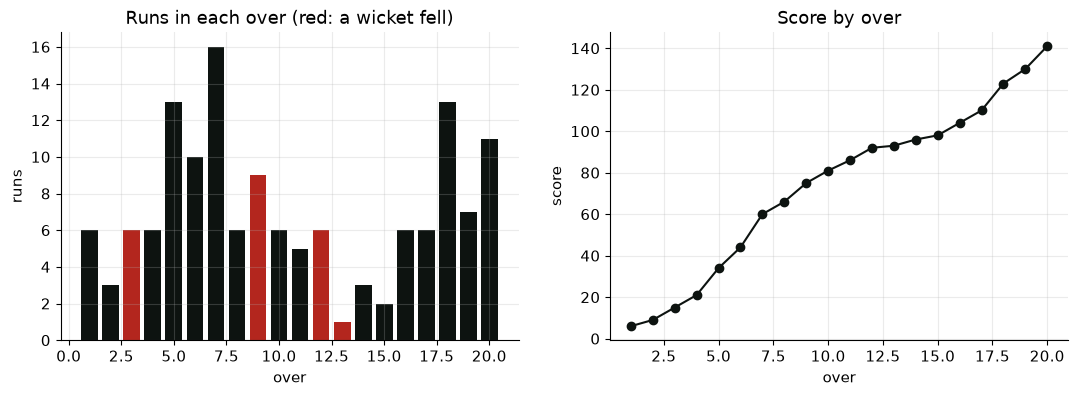

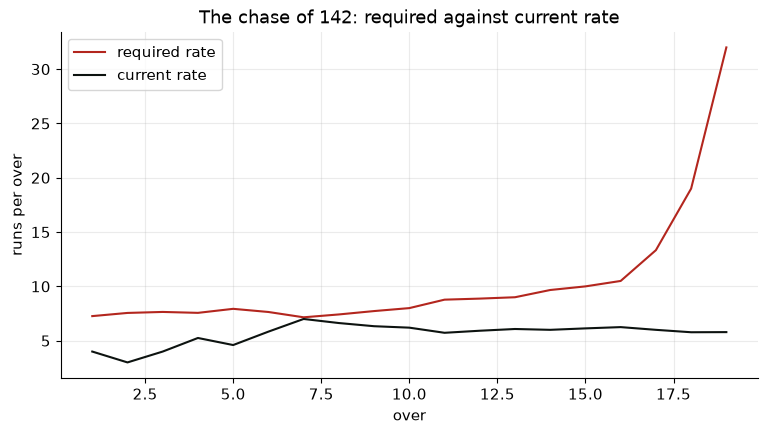

Northfield won by 31 runs


In [5]:
o = pd.DataFrame(card["over_by_over"])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(o["over"], o["runs"], color=[RED if w else INK for w in o["wickets"]])
axes[0].set_xlabel("over"); axes[0].set_ylabel("runs"); axes[0].set_title("Runs in each over (red: a wicket fell)")
axes[1].plot(o["over"], o["total"], marker="o", color=INK); axes[1].set_xlabel("over"); axes[1].set_ylabel("score"); axes[1].set_title("Score by over")
plt.show()

chase = innings(1, 2); target = card["total"] + 1
second = pd.DataFrame(chase["over_by_over"])
second["balls_left"] = 120 - second["over"] * 6
second["required_rate"] = [scoring.required_run_rate(target, t, b) for t, b in zip(second["total"], second["balls_left"])]
second["current_rate"] = second["total"] / second["over"]
fig, ax = plt.subplots()
ax.plot(second["over"], second["required_rate"], color=RED, label="required rate"); ax.plot(second["over"], second["current_rate"], color=INK, label="current rate")
ax.set_xlabel("over"); ax.set_ylabel("runs per over"); ax.set_title(f"The chase of {target}: required against current rate"); ax.legend(); plt.show()
print(scoring.match_result(card, chase, "Northfield", "Us") if card["batting"][0]["player"].startswith("Northfield") else "")

## 4. Partnerships

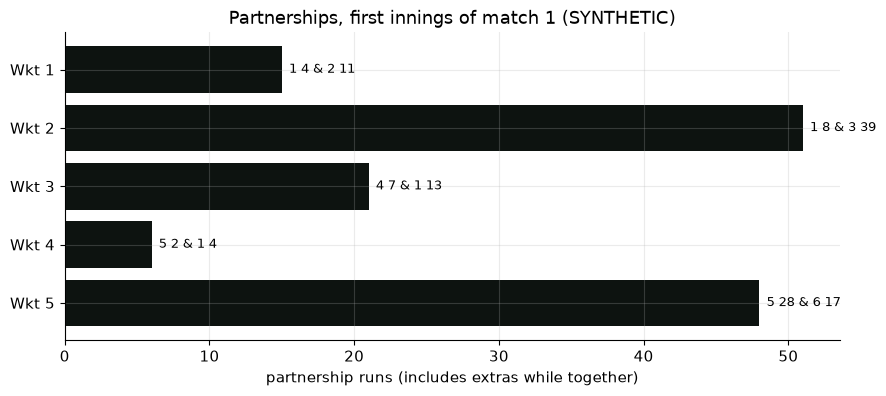

In [6]:
p = pd.DataFrame(card["partnerships"])
p["pair"] = p["contrib"].apply(lambda c: " & ".join(f"{x['player'].split()[-1]} {x['runs']}" for x in c))
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh([f"Wkt {w}" for w in p["wicket"]][::-1], p["runs"][::-1], color=INK)
for i, (r, t) in enumerate(zip(p["runs"][::-1], p["pair"][::-1])): ax.text(r + 0.5, i, t, va="center", fontsize=9)
ax.set_xlabel("partnership runs (includes extras while together)"); ax.set_title("Partnerships, first innings of match 1 (SYNTHETIC)"); plt.show()

## 5. Every match, every player

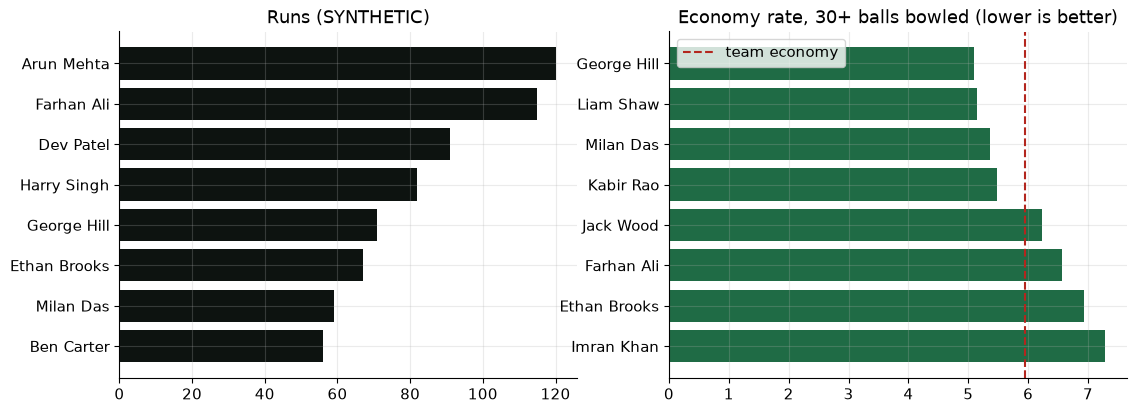

,overs,runs,wickets,average,economy,strike_rate,best
player,,,,,,,
Liam Shaw,21.0,108,8,13.50,5.14,15.75,2/16
Kabir Rao,19.0,104,8,13.00,5.47,14.25,3/10
George Hill,16.4,85,7,12.14,5.10,14.29,4/17
Milan Das,19.0,102,7,14.57,5.37,16.29,3/1
Farhan Ali,21.0,138,7,19.71,6.57,18.00,3/20
Imran Khan,14.0,102,7,14.57,7.29,12.00,4/14
Jack Wood,17.5,111,5,22.20,6.22,21.40,2/15
Ethan Brooks,15.0,104,4,26.00,6.93,22.50,1/5


In [7]:
lines = scoring.lines_from_balls(balls.to_dict("records"))
bat = [r for r in lines["batting"] if r["player"] in ours]
bowl = [r for r in lines["bowling"] if r["player"] in ours]
batting = pd.DataFrame(stats.career_batting(bat)).set_index("player")
bowling = pd.DataFrame(stats.career_bowling(bowl)).set_index("player")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
b = batting.sort_values("runs").tail(8); axes[0].barh(b.index, b["runs"], color=INK); axes[0].set_title("Runs (SYNTHETIC)")
e = bowling[bowling["legal_balls"] >= 30].sort_values("economy", ascending=False); axes[1].barh(e.index, e["economy"], color=GREEN)
axes[1].axvline(bowling["runs"].sum() * 6 / bowling["legal_balls"].sum(), color=RED, ls="--", label="team economy"); axes[1].legend()
axes[1].set_title("Economy rate, 30+ balls bowled (lower is better)"); plt.show()
bowling[["overs", "runs", "wickets", "average", "economy", "strike_rate", "best"]].sort_values("wickets", ascending=False).round(2)

## 6. Comparing two players

In [8]:
a, b = "Arun Mehta", "Farhan Ali"
cmp = pd.DataFrame({a: batting.loc[a, ["innings", "runs", "average", "strike_rate", "highest", "fours", "sixes"]],
                    b: batting.loc[b, ["innings", "runs", "average", "strike_rate", "highest", "fours", "sixes"]]})
display(cmp)
print(f"{b} also bowls: {bowling.loc[b, 'wickets']} wickets at an economy of {bowling.loc[b, 'economy']:.2f}.")
print("With this few innings, differences of a few runs in the average are within chance.")

,Arun Mehta,Farhan Ali
innings,7.000000,6.000000
runs,120.000000,115.000000
average,17.142857,19.166667
strike_rate,127.659574,115.000000
highest,41.000000,32.000000
fours,13.000000,8.000000
sixes,4.000000,7.000000


Farhan Ali also bowls: 7 wickets at an economy of 6.57.
With this few innings, differences of a few runs in the average are within chance.


## 7. Team selection

The selection assistant never produces a rating. It picks the keeper, then the bowling attack, then the best remaining batters, and writes the figure behind each choice. Minimum samples keep one good innings from deciding a place.

In [9]:
squad = []
for _, pl in players.iterrows():
    squad.append({"id": pl["name"], "name": pl["name"], "role": pl["role"], "bowl_style": pl["bowl_style"] if isinstance(pl["bowl_style"], str) else None,
                  "bat": batting.loc[pl["name"]].to_dict() if pl["name"] in batting.index else None,
                  "bowl": bowling.loc[pl["name"]].to_dict() if pl["name"] in bowling.index else None})
available = [p for p in squad if p["name"] not in ("Noah Reid", "Omar Aziz")]        # two players unavailable
pick = selection.select_xi(available, match_overs=20)
for r in pick["reasons"]:
    print(f"- {r['player']} ({r['role']}): {r['reason']}")
print("\nLeft out:", [x["player"] for x in pick["left_out"]])
a = pick["analysis"]
print(f"\nBatting depth {a['batting_depth']}, bowling options {a['bowling_options']} ({len(a['pace_options'])} pace, {len(a['spin_options'])} spin), overs covered {a['overs_covered']} of 20")
for w in a["warnings"]: print("Warning:", w)
print("\nAssumptions:"); [print(" -", x) for x in pick["assumptions"]]

- Dev Patel (wicket_keeper): Wicket-keeper (only keeper available). Batting average 11.4 from 8 innings.
- George Hill (all_rounder): Spin leg. Bowling average 12.1, economy 5.10, 7 wickets in 16.4 overs.
- Kabir Rao (bowler): Spin off. Bowling average 13.0, economy 5.47, 8 wickets in 19.0 overs.
- Liam Shaw (bowler): Pace medium. Bowling average 13.5, economy 5.14, 8 wickets in 21.0 overs.
- Milan Das (all_rounder): Pace medium. Bowling average 14.6, economy 5.37, 7 wickets in 19.0 overs.
- Imran Khan (bowler): Pace fast. Bowling average 14.6, economy 7.29, 7 wickets in 14.0 overs.
- Farhan Ali (all_rounder): Batting average 19.2, strike rate 115, 115 runs in 6 innings.
- Arun Mehta (batter): Batting average 17.1, strike rate 128, 120 runs in 7 innings.
- Harry Singh (batter): Batting average 11.7, strike rate 85, 82 runs in 8 innings.
- Ethan Brooks (batter): Batting average 11.2, strike rate 86, 67 runs in 6 innings.
- Ben Carter (batter): Batting average 9.3, strike rate 110, 56 ru

[None, None, None, None, None]

In [10]:
# Compare the suggested side with an alternative that swaps one bowler for a batter.
names = [p["name"] for p in pick["xi"]]
alt = [p for p in available if p["name"] in names]
bench = [p for p in available if p["name"] not in names]
alt[-1] = bench[0]
cmp = selection.compare_xis([p for p in available if p["name"] in names], alt)
pd.DataFrame(cmp["differences"]).T
matches_summary = pd.DataFrame({"match": matches["match_id"], "result": matches["result"], "ours": matches["our_score"], "theirs": matches["their_score"]})
matches_summary.to_csv(EXPORTS / "match_results.csv", index=False)
bowling.round(2).to_csv(EXPORTS / "bowling_by_player.csv")

## Summary

### Key findings
- The scoring engine's scorecards add up in two ways: batters' runs plus extras equal the total, and bowlers' runs plus byes and leg-byes equal the total.
- Partnerships, over-by-over runs and the chase can all be rebuilt from the balls.
- The selection assistant lists the number behind every pick and warns when the side lacks a keeper, a spinner or five bowlers.

### Interpretation
Selection from season statistics is a starting point. With six or seven innings each, many players cannot be separated by their numbers, and the coach's knowledge of form, fitness and the opposition should decide.

### Limitations
- Averages and economy rates over a few matches are noisy.
- Selection looks only at batting and bowling records, not fielding, fitness or the opposition.
- Partnership runs include extras, so they can differ from the sum of the two batters' scores.
- The synthetic matches are generated, so none of these players' numbers are real.

### How this notebook connects to the application
The Match Center's scorecards, partnerships, over strips and chase panel come from `scoring.score_innings`, the same function used here. The Team Hub's Selection assistant calls `selection.select_xi` and `compare_xis` through `POST /api/team/select` and `/api/team/compare`.